# Ejercicio Regression Tree
Son datos de temperaturas tomados de la ciudad de Seattle. El objetivo es intentar predecir lo mejor posible la máxima temperatura (columna `actual`) que alcanzaremos al día siguiente. Para ello contaremos con temperaturas de los dos días anteriores, históricos de máximas temperaturas y un amigo bastante chapas que te da su predicción del tiempo cada día.

**Resumen de datos**:
* year: 2016 for all data points
* month: number for month of the year
* day: number for day of the year
* week: day of the week as a character string
* temp_2: max temperature 2 days prior
* temp_1: max temperature 1 day prior
* average: historical average max temperature
* actual: max temperature measurement
* friend: your friend’s prediction, a random number between 20 below the average and 20 above the average


### 1. Importa el csv "temps.csv"

In [435]:
import numpy as np
import os
import sklearn
import pandas as pd

In [436]:
temperatura = pd.read_csv("data/temps.csv")

### 2. Realiza un análisis exploratorio junto con un Feature Engineering

In [437]:
temperatura.head() # muestra las primeras cinco filas para conocer las variables y sus valores

,year,month,day,week,temp_2,temp_1,average,actual,friend
0,2016,1,1,Fri,45,45,45.6,45,29
1,2016,1,2,Sat,44,45,45.7,44,61
2,2016,1,3,Sun,45,44,45.8,41,56
3,2016,1,4,Mon,44,41,45.9,40,53
4,2016,1,5,Tues,41,40,46.0,44,41


In [438]:
temperatura.info() # comprobar los tipos de datos y si hay valores nulos

<class 'pandas.DataFrame'>
RangeIndex: 348 entries, 0 to 347
Data columns (total 9 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   year     348 non-null    int64  
 1   month    348 non-null    int64  
 2   day      348 non-null    int64  
 3   week     348 non-null    str    
 4   temp_2   348 non-null    int64  
 5   temp_1   348 non-null    int64  
 6   average  348 non-null    float64
 7   actual   348 non-null    int64  
 8   friend   348 non-null    int64  
dtypes: float64(1), int64(7), str(1)
memory usage: 24.6 KB


In [439]:
temperatura. describe() # descripción estadística

,year,month,day,temp_2,temp_1,average,actual,friend
count,348.0,348.000000,348.000000,348.000000,348.000000,348.000000,348.000000,348.000000
mean,2016.0,6.477011,15.514368,62.652299,62.701149,59.760632,62.543103,60.034483
std,0.0,3.498380,8.772982,12.165398,12.120542,10.527306,11.794146,15.626179
min,2016.0,1.000000,1.000000,35.000000,35.000000,45.100000,35.000000,28.000000
25%,2016.0,3.000000,8.000000,54.000000,54.000000,49.975000,54.000000,47.750000
50%,2016.0,6.000000,15.000000,62.500000,62.500000,58.200000,62.500000,60.000000
75%,2016.0,10.000000,23.000000,71.000000,71.000000,69.025000,71.000000,71.000000
max,2016.0,12.000000,31.000000,117.000000,117.000000,77.400000,92.000000,95.000000


In [440]:
temperatura.select_dtypes(include='number').corr()['actual'] # identificar qué variables numéricas tienen una mayor relación lineal con la temperatura que quieres predecir

# correlación de Pearson entre cada variable numérica y actual, que es la temperatura máxima que queremos predecir

year            NaN
month      0.004529
day       -0.021675
temp_2     0.805835
temp_1     0.877880
average    0.848365
actual     1.000000
friend     0.569145
Name: actual, dtype: float64

-La temperatura máxima del día anterior (temp_1) es la variable con mayor correlación lineal con actual

-La temperatura histórica media (average) y la temperatura de dos días antes (temp_2) también muestran una relación muy fuerte con la temperatura que queremos predecir

-La predicción de tu amigo (friend) tiene una correlación moderada. Podría aportar información al modelo

-month y day presentan correlaciones cercanas a cero, pero eso no significa que no sean útiles. Pearson mide relaciones lineales y la temperatura tiene un comportamiento estacional que puede no ser lineal. Un árbol de regresión puede detectar esas relaciones.

In [441]:
pd.get_dummies(temperatura['week']) 

# convierte los días de la semana en variables numéricas de 0 y 1

,Fri,Mon,Sat,Sun,Thurs,Tues,Wed
0,True,False,False,False,False,False,False
1,False,False,True,False,False,False,False
2,False,False,False,True,False,False,False
3,False,True,False,False,False,False,False
4,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...
343,False,False,False,False,False,True,False
344,False,False,False,False,False,False,True
345,False,False,False,False,True,False,False
346,True,False,False,False,False,False,False


In [442]:
dias = {
    'Mon': 1,
    'Tues': 2,
    'Wed': 3,
    'Thurs': 4,
    'Fri': 5,
    'Sat': 6,
    'Sun': 7
}

In [434]:
temperatura['week_encoded'] = encoder.fit_transform(temperatura['week'].map(dias))
temperatura

,month,day,week,temp_2,temp_1,average,actual,friend,week_encoded,calor
0,1,1,Fri,45,45,45.6,45,29,4,0
1,1,2,Sat,44,45,45.7,44,61,5,0
2,1,3,Sun,45,44,45.8,41,56,6,0
3,1,4,Mon,44,41,45.9,40,53,0,0
4,1,5,Tues,41,40,46.0,44,41,1,0
...,...,...,...,...,...,...,...,...,...,...
343,12,27,Tues,42,42,45.2,47,47,1,0
344,12,28,Wed,42,47,45.3,48,58,2,0
345,12,29,Thurs,47,48,45.3,48,65,3,0
346,12,30,Fri,48,48,45.4,57,42,4,0


In [445]:
temperatura['week'] = temperatura['week'].map(dias)

In [446]:
temperatura.head()

,year,month,day,week,temp_2,temp_1,average,actual,friend
0,2016,1,1,NaN,45,45,45.6,45,29
1,2016,1,2,NaN,44,45,45.7,44,61
2,2016,1,3,NaN,45,44,45.8,41,56
3,2016,1,4,NaN,44,41,45.9,40,53
4,2016,1,5,NaN,41,40,46.0,44,41


In [447]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

In [448]:
temperatura['week_encoded'] = encoder.fit_transform(temperatura['week'])
temperatura

,year,month,day,week,temp_2,temp_1,average,actual,friend,week_encoded
0,2016,1,1,NaN,45,45,45.6,45,29,0
1,2016,1,2,NaN,44,45,45.7,44,61,0
2,2016,1,3,NaN,45,44,45.8,41,56,0
3,2016,1,4,NaN,44,41,45.9,40,53,0
4,2016,1,5,NaN,41,40,46.0,44,41,0
...,...,...,...,...,...,...,...,...,...,...
343,2016,12,27,NaN,42,42,45.2,47,47,0
344,2016,12,28,NaN,42,47,45.3,48,58,0
345,2016,12,29,NaN,47,48,45.3,48,65,0
346,2016,12,30,NaN,48,48,45.4,57,42,0


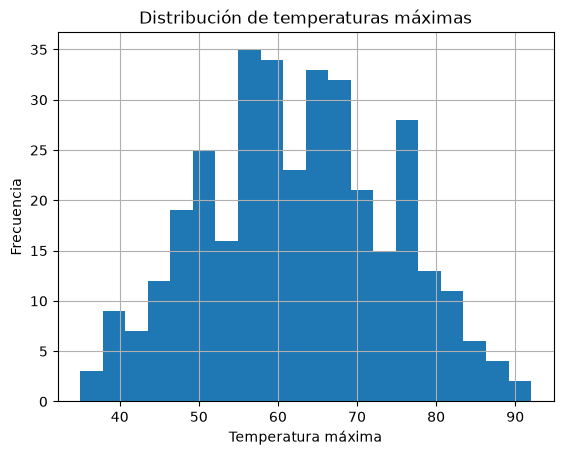

In [449]:
import matplotlib.pyplot as plt

temperatura['actual'].hist(bins=20)
plt.xlabel('Temperatura máxima')
plt.ylabel('Frecuencia')
plt.title('Distribución de temperaturas máximas')
plt.show()

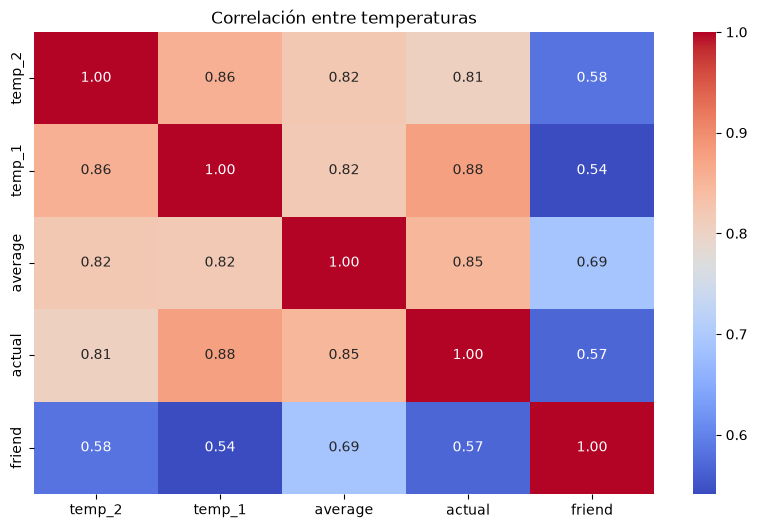

In [450]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))

sns.heatmap(
    temperatura[['temp_2', 'temp_1', 'average', 'actual', 'friend']].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlación entre temperaturas')
plt.show()

# variables más relevantes. Observar mejor las relaciones entre las variables meteorológicas

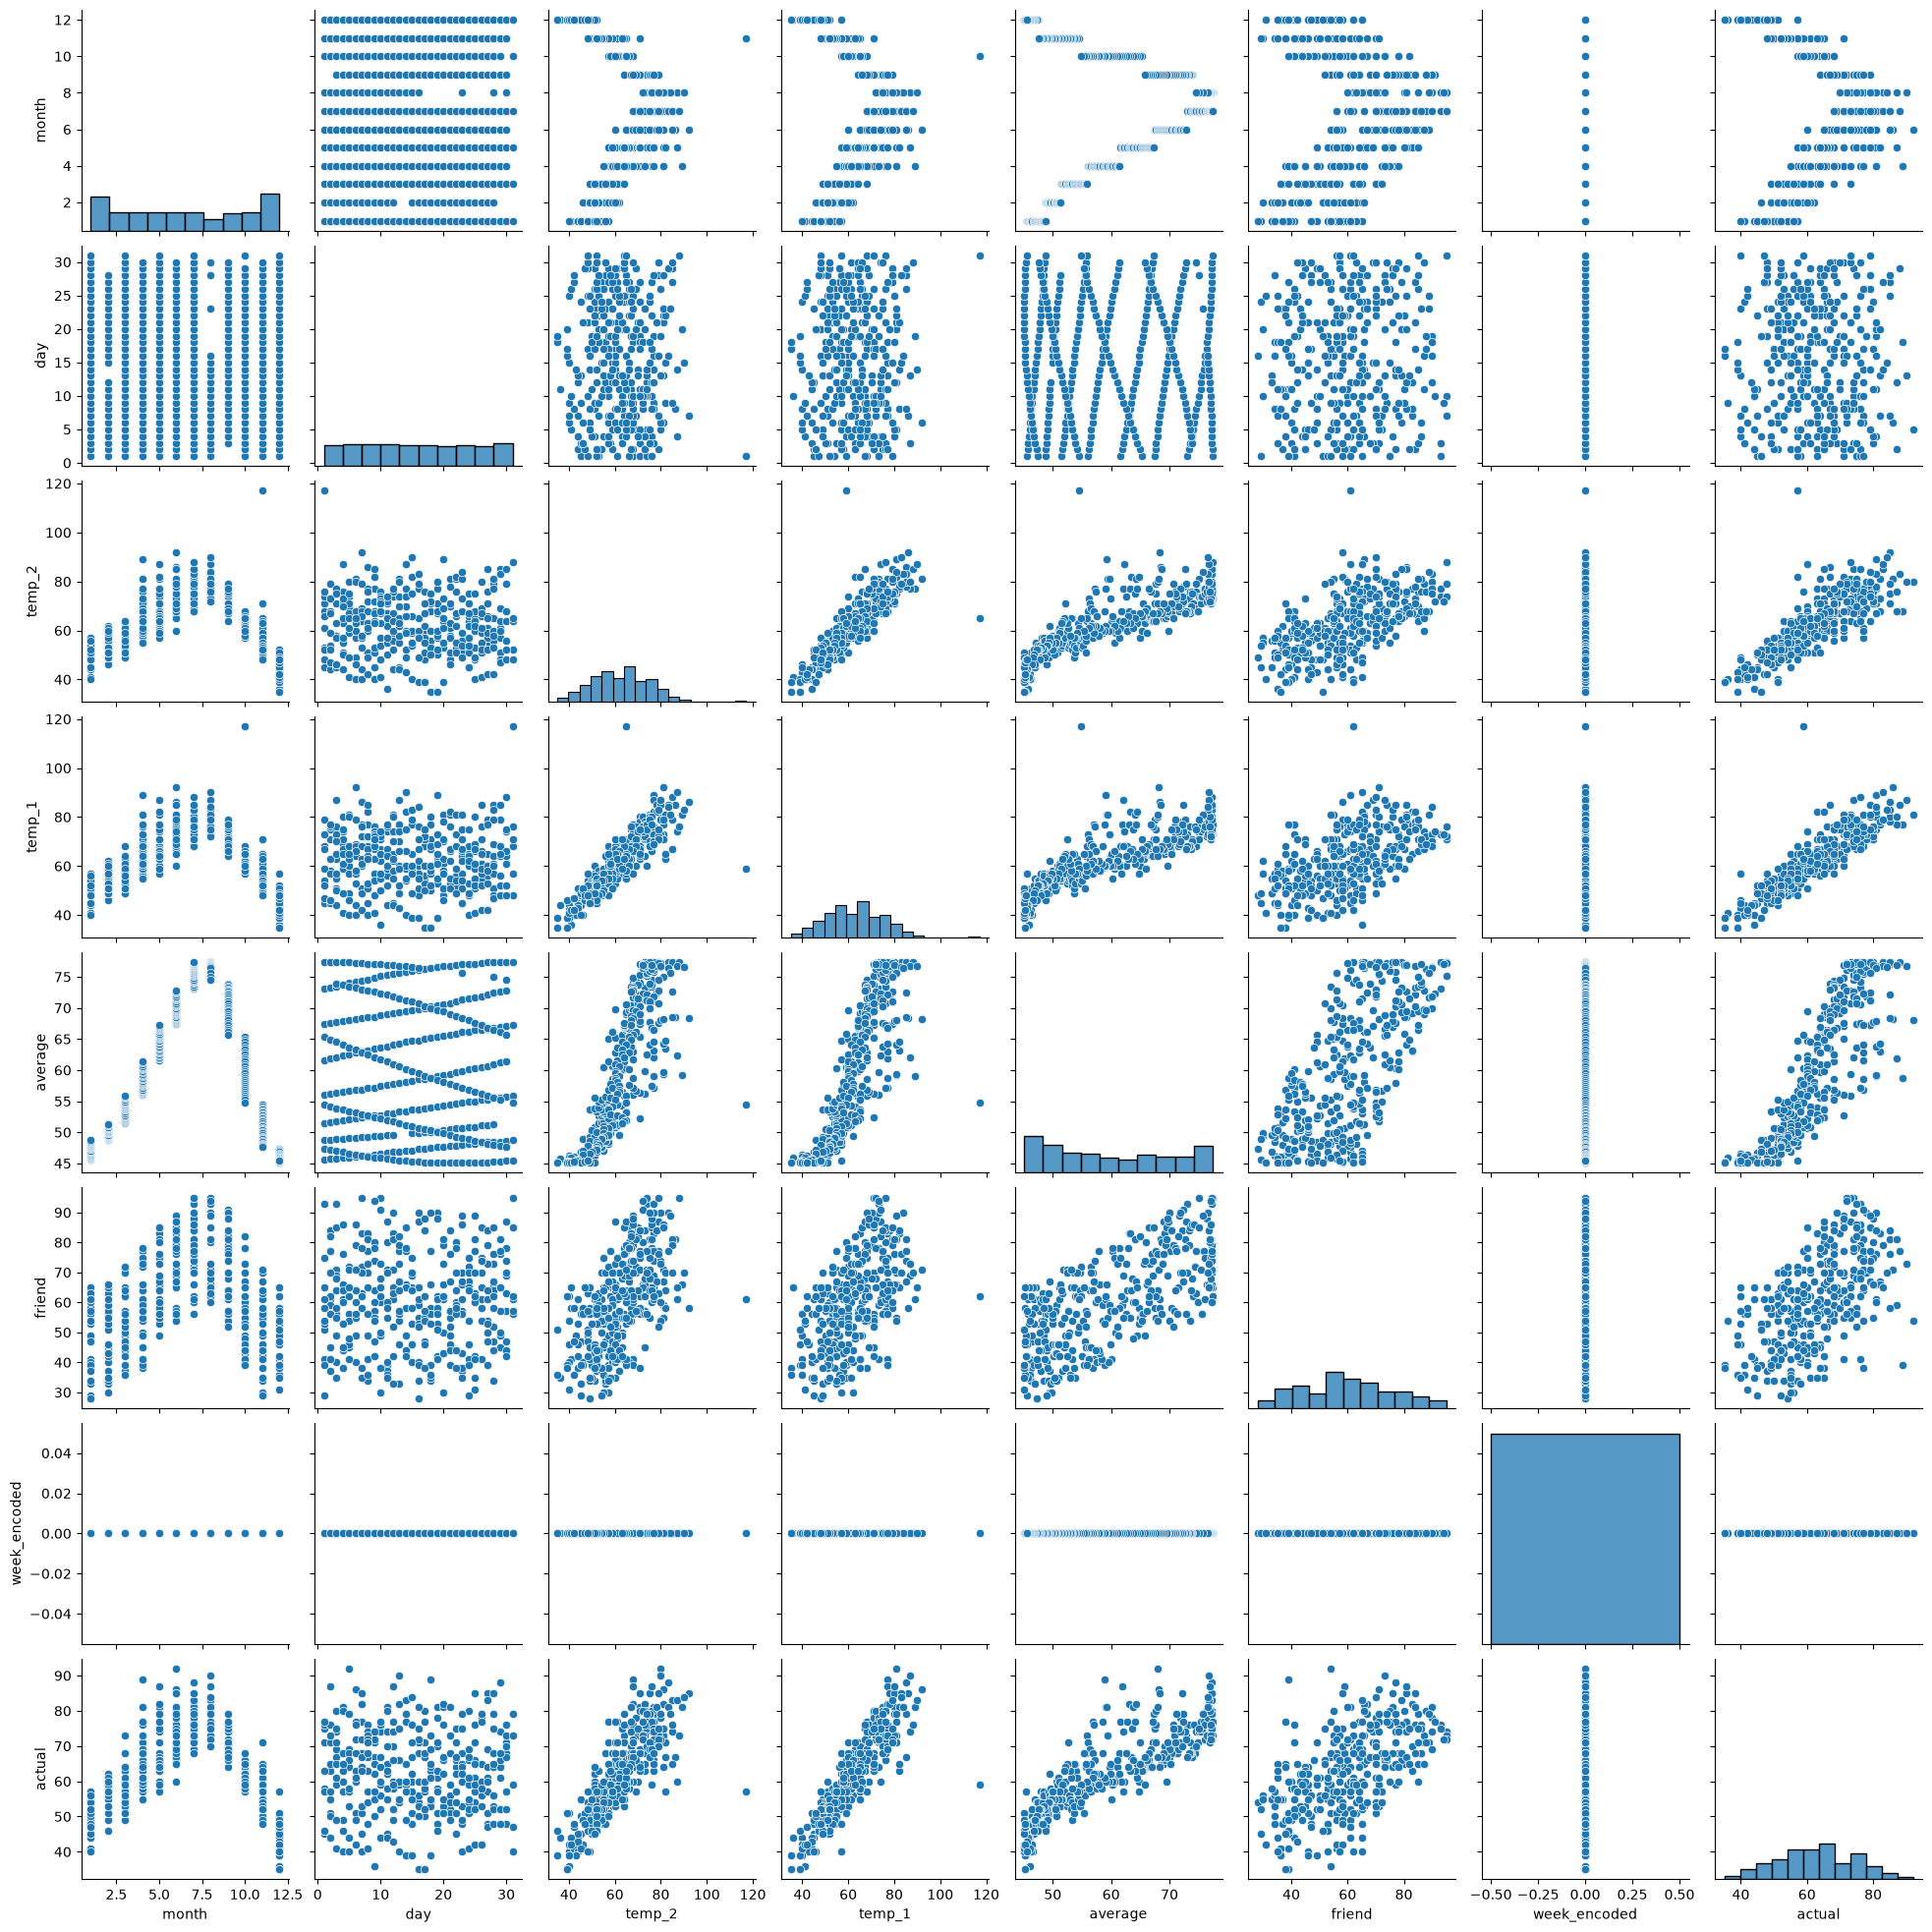

In [451]:
sns.pairplot(
    temperatura[
        ['month', 'day', 'temp_2', 'temp_1', 'average', 'friend','week_encoded', 'actual']
    ]
)


In [452]:
temperatura = temperatura.drop(columns=['year'])

# eliminar 'year' porque siempre tiene el mismo valor y no aporta información al modelo

Conclusiones

El dataset contiene 348 observaciones correspondientes al año 2016.

La temperatura máxima del día anterior (temp_1) es la variable que presenta mayor correlación lineal con la temperatura que queremos predecir (actual), con un coeficiente de 0.879.

La temperatura histórica media (average) y la temperatura de dos días antes (temp_2) también muestran correlaciones positivas elevadas, de 0.848 y 0.806, respectivamente.

La predicción del amigo (friend) presenta una correlación moderada de 0.569.

Las variables month y day muestran correlaciones lineales prácticamente nulas con actual, aunque podrían aportar información temporal al modelo.

Se ha aplicado One-Hot Encoding a la variable categórica week para convertir los días de la semana en variables numéricas.

Se ha eliminado year porque es constante en todo el dataset y no aporta capacidad predictiva.

### 3. Selecciona variables y divide en train y test

In [453]:
X = temperatura[['month', 'day', 'temp_2', 'temp_1', 'average', 'friend','week_encoded']]
y = temperatura['actual']

# X (features): variables que utilizaremos para predecir la temperatura máxima.
# y (target): variable que queremos predecir, en este caso actual.

In [454]:
from sklearn.model_selection import train_test_split

In [455]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False) # False, respetar el orden cronológico

In [456]:
print('X_train:', X_train.shape)
print('X_test:', X_test.shape)
print('y_train:', y_train.shape)
print('y_test:', y_test.shape)

# comprobar la división 

X_train: (278, 7)
X_test: (70, 7)
y_train: (278,)
y_test: (70,)


Esto supone que se ha eliminado year, convertido week en siete columnas y no se han añadido otras variables

Importante: shuffle=False conserva el orden de las filas, la división es cronológica siempre que el dataset esté ordenado de la fecha más antigua a la más reciente

### 4. Entrena el modelo


In [457]:
from sklearn.tree import DecisionTreeRegressor

In [458]:
modelo = DecisionTreeRegressor(random_state=42, max_depth=2)

# creación del modelo para entrenar

In [459]:
modelo.fit(X_train, y_train)

# entrenar el modelo 

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

In [460]:
y_pred = modelo.predict(X_test)

# comparar las predicciones con los valores reales

In [461]:
comparacion = pd.DataFrame({
    'Real': y_test,
    'Prediccion': y_pred
})

comparacion.head(10)

# cuánto se aproxima el modelo a las temperaturas reales

,Real,Prediccion
278,62,63.365079
279,62,63.365079
280,61,63.365079
281,65,63.365079
282,58,63.365079
283,60,63.365079
284,65,63.365079
285,68,53.176471
286,59,78.717391
287,57,53.176471


### 5. Evaluación de tu modelo
Calcula el coeficiente de determinación. 

Calcula el MAE, MAPE, MSE y RMSE.

In [462]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error, mean_squared_error


In [463]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

In [464]:
print('R²:', round(r2, 3)) # Mide cuánto de la variabilidad de la temperatura explica el modelo. Cuanto más cerca de 1, mejor. Puede ser negativo.
print('MAE:', round(mae, 3)) # 	Error absoluto medio. Indica cuánto se equivoca el modelo de media, en las unidades originales
print('MAPE:', round(mape * 100, 2), '%') # Error porcentual absoluto medio. Expresa el error medio en porcentaje.
print('MSE:', round(mse, 3)) # Error cuadrático medio. Penaliza especialmente las predicciones con errores grandes.
print('RMSE:', round(rmse, 3)) # Raíz cuadrada del MSE. Expresa el error en las mismas unidades que la temperatura.


R²: 0.01
MAE: 7.213
MAPE: 15.44 %
MSE: 80.254
RMSE: 8.958


In [465]:
y_pred_train = modelo.predict(X_train)

print('R² Train:', r2_score(y_train, y_pred_train))
print('R² Test:', r2_score(y_test, y_pred))

R² Train: 0.7669442571102024
R² Test: 0.01016533016078891


- R²	0.652	El modelo explica aproximadamente el 65,2 % de la variabilidad de la temperatura
- MAE	4.329	Se equivoca una media de 4,33 °F
- MAPE	8.76 %	Error porcentual absoluto medio del 8,76 %
- MSE	28.214	Error cuadrático medio
- RMSE	5.312	Error típico de predicción de aproximadamente 5,31 °F

### 6. Representa el árbol de decisión

In [466]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

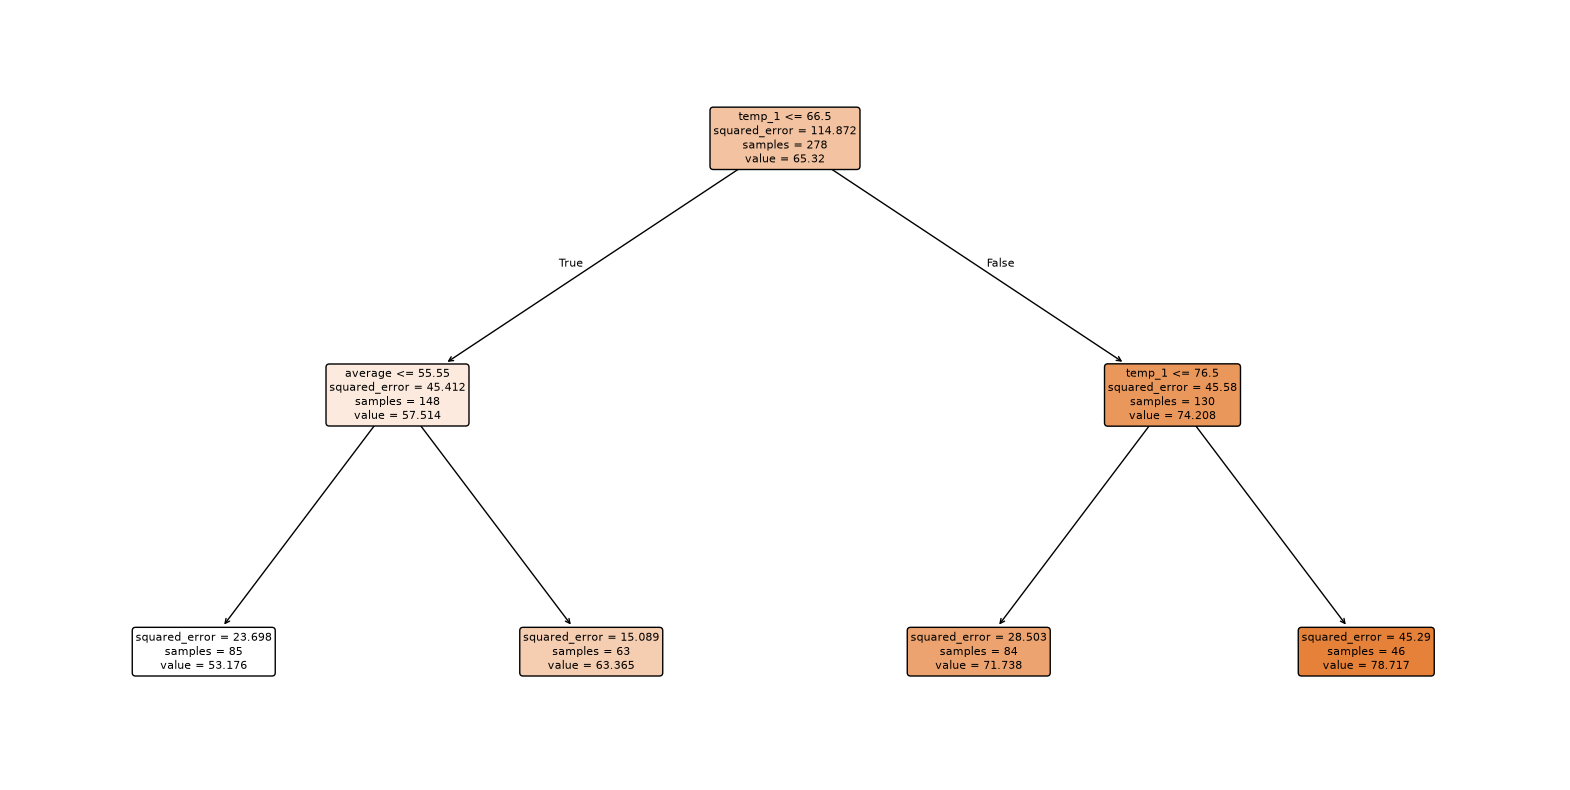

In [467]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))

plot_tree(
    modelo,
    feature_names=X_train.columns,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.show()

### 7. Modifica el max_depth a 3 y vuelve a entrenarlo

In [468]:
modelo_modificado = DecisionTreeRegressor(random_state=42, max_depth=3)

### 8. Vuelve a evaluar tu modelo

In [469]:
modelo_modificado.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

In [470]:
y_pred = modelo_modificado.predict(X_test)

In [471]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

In [472]:
print('R²:', round(r2, 3)) # Mide cuánto de la variabilidad de la temperatura explica el modelo. Cuanto más cerca de 1, mejor. Puede ser negativo.
print('MAE:', round(mae, 3)) # 	Error absoluto medio. Indica cuánto se equivoca el modelo de media, en las unidades originales
print('MAPE:', round(mape * 100, 2), '%') # Error porcentual absoluto medio. Expresa el error medio en porcentaje.
print('MSE:', round(mse, 3)) # Error cuadrático medio. Penaliza especialmente las predicciones con errores grandes.
print('RMSE:', round(rmse, 3)) # Raíz cuadrada del MSE. Expresa el error en las mismas unidades que la temperatura.

R²: 0.461
MAE: 5.174
MAPE: 11.07 %
MSE: 43.693
RMSE: 6.61


In [473]:
y_pred_train = modelo_modificado.predict(X_train)

print('R² Train:', r2_score(y_train, y_pred_train))
print('R² Test:', r2_score(y_test, y_pred))

R² Train: 0.818617476323072
R² Test: 0.461104504784289


### 9. Vuelve a representar su árbol

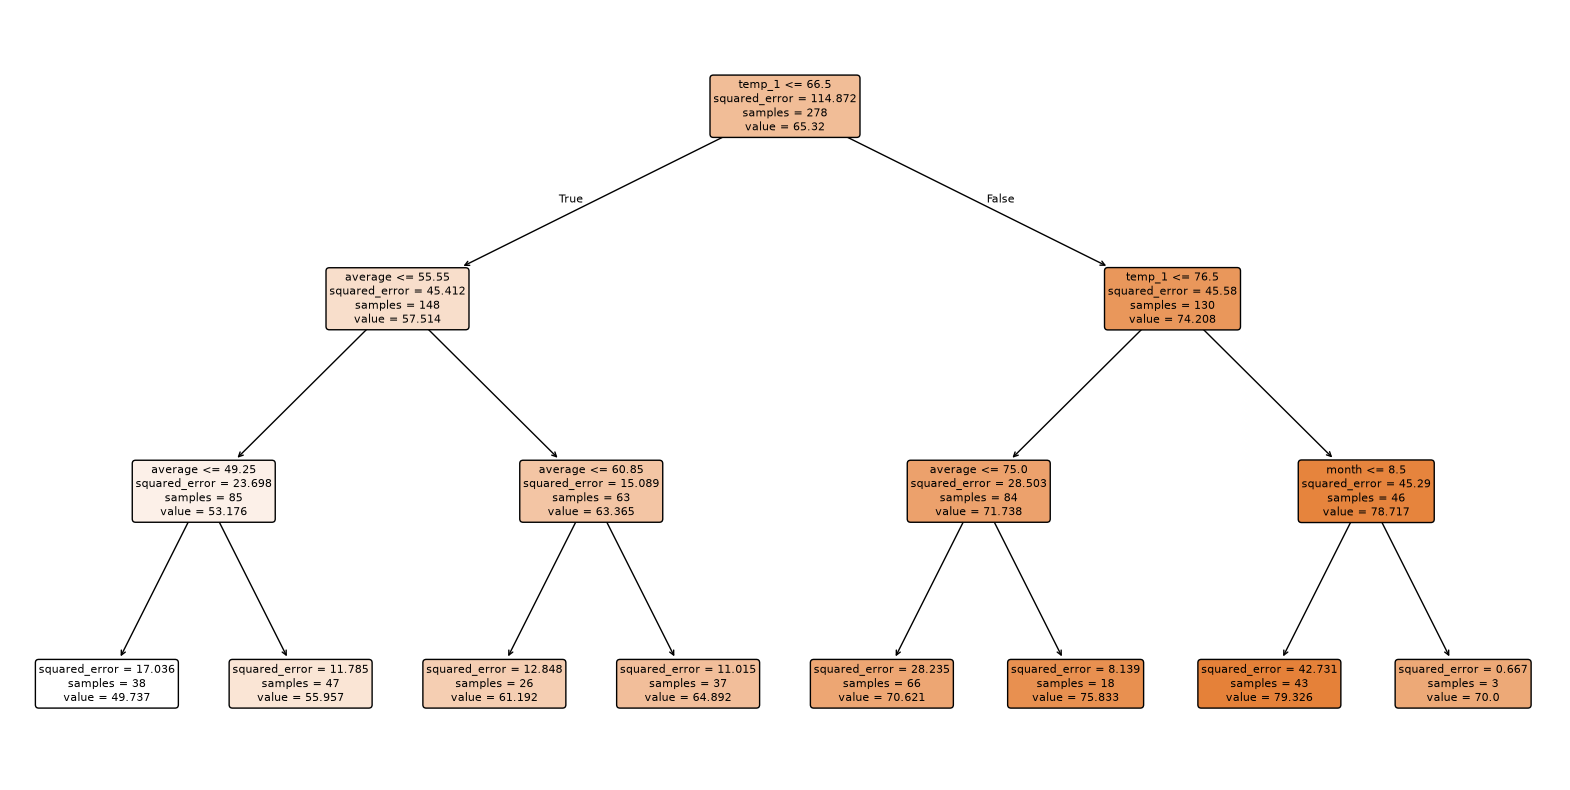

In [474]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))

plot_tree(
    modelo_modificado,
    feature_names=X_train.columns,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.show()

### 10. Utiliza un grid search con cross validation para hiperparametrizar tu modelo

In [475]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.tree import DecisionTreeRegressor

In [476]:
param_grid = {
    'max_depth': [2, 3, 4, 5, 6, 8, 10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

In [477]:
tscv = TimeSeriesSplit(n_splits=5)

grid_search = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=param_grid,
    cv=tscv,
    scoring='r2',
    n_jobs=-1
)

In [478]:
grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 3, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose

In [479]:
print('Mejores parámetros:', grid_search.best_params_)
print('Mejor R² de validación:', grid_search.best_score_)

Mejores parámetros: {'max_depth': 3, 'min_samples_leaf': 4, 'min_samples_split': 10}
Mejor R² de validación: 0.06260637346547634


In [480]:
# GridSearchCV guarda automáticamente el mejor modelo reentrenado con todo el conjunto Train, porque refit=True es su valor predeterminado.

mejor_modelo = grid_search.best_estimator_

y_pred_grid = mejor_modelo.predict(X_test)

print('R² Test:', r2_score(y_test, y_pred_grid))
print('MAE Test:', mean_absolute_error(y_test, y_pred_grid))
print('RMSE Test:', np.sqrt(mean_squared_error(y_test, y_pred_grid)))

R² Test: 0.423351132034926
MAE Test: 5.278117894513617
RMSE Test: 6.837671295628992


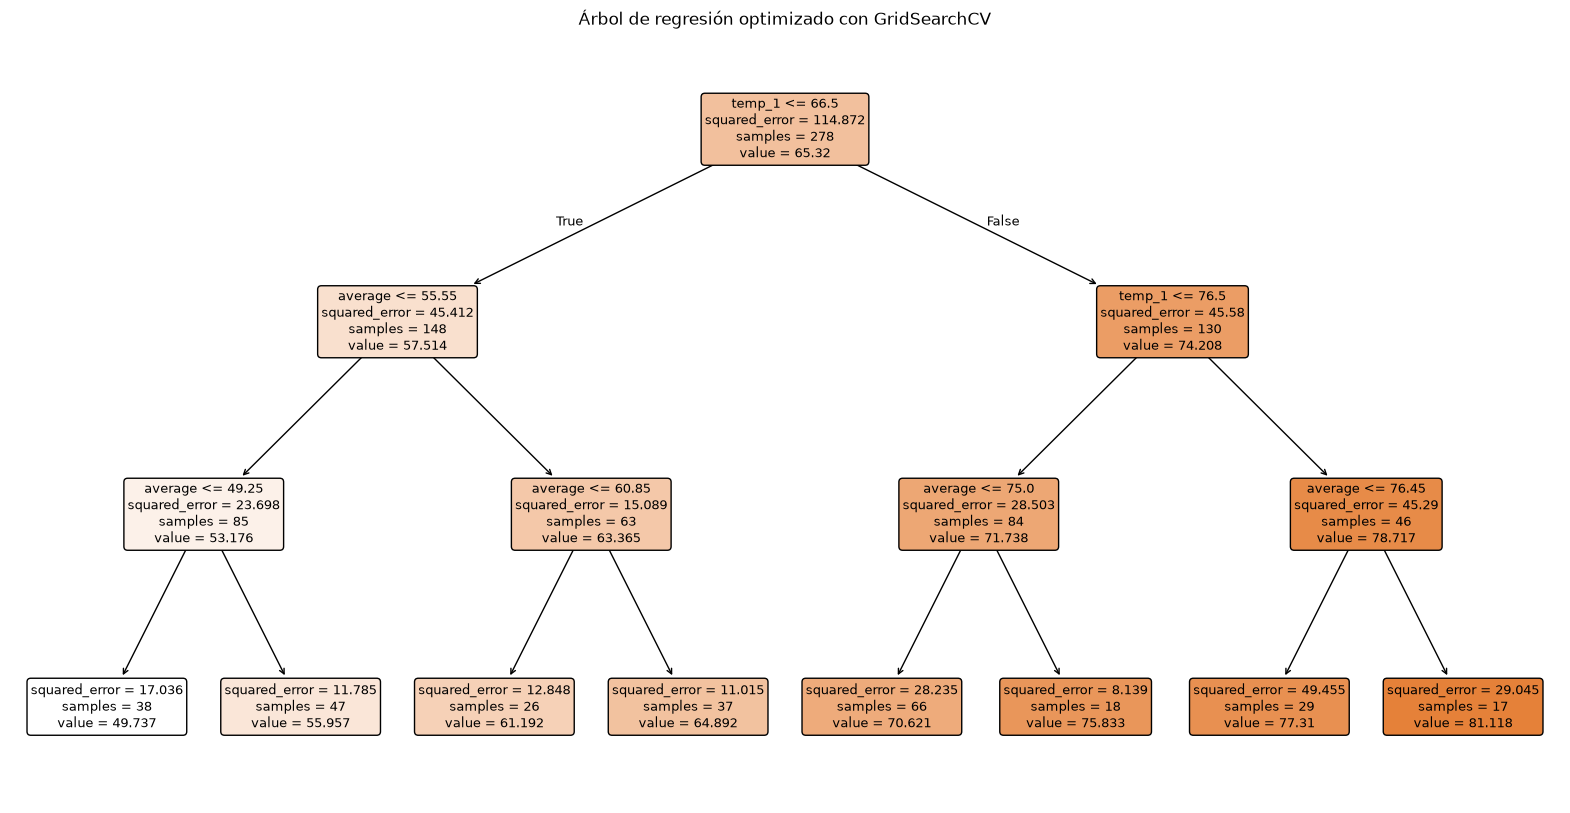

In [481]:
plt.figure(figsize=(20, 10))

plot_tree(
    mejor_modelo,
    feature_names=X_train.columns,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title('Árbol de regresión optimizado con GridSearchCV')
plt.show()

### 11. Obten el `feature_importances` de cada variable en el último modelo

In [482]:
mejor_modelo.feature_importances_

array([0.        , 0.        , 0.        , 0.79589605, 0.20410395,
       0.        , 0.        ])

In [483]:
importancias = pd.DataFrame({
    'Variable': X_train.columns,
    'Importancia': mejor_modelo.feature_importances_
})

importancias = importancias.sort_values(
    by='Importancia',
    ascending=False
)

importancias

,Variable,Importancia
3,temp_1,0.795896
4,average,0.204104
0,month,0.000000
2,temp_2,0.000000
1,day,0.000000
5,friend,0.000000
6,week_encoded,0.000000


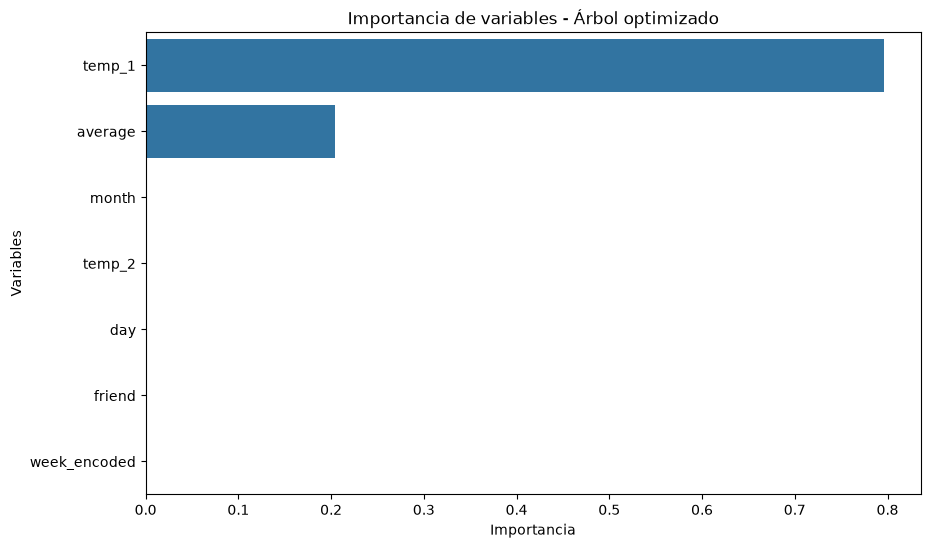

In [484]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importancias,
    x='Importancia',
    y='Variable'
)

plt.title('Importancia de variables - Árbol optimizado')
plt.xlabel('Importancia')
plt.ylabel('Variables')
plt.show()

In [485]:
print("Mejores parámetros:", grid_search.best_params_)
print("R² Train:", mejor_modelo.score(X_train, y_train))
print("R² Test:", mejor_modelo.score(X_test, y_test))

Mejores parámetros: {'max_depth': 3, 'min_samples_leaf': 4, 'min_samples_split': 10}
R² Train: 0.8158452481051611
R² Test: 0.423351132034926


- El análisis de feature_importances_ muestra que la temperatura del día anterior (temp_1) es la variable más relevante para predecir la temperatura máxima, con una importancia del 79,40 %.

- La segunda variable más importante es la temperatura histórica media (average)

- Ambas variables concentran conjuntamente el 99,17 % de la importancia total del modelo.

- La variable week_encoded presenta una contribución muy reducida (0,83 %), mientras que month, day y temp_2 no son utilizadas en las divisiones del árbol optimizado.

- Estos resultados muestran que el modelo basa prácticamente todas sus decisiones en la temperatura del día anterior y la temperatura histórica media.

### 12. Construye un nuevo modelo `DecisionTreeClassifier` que te clasifique cuando en un día va a hacer una temperatura mayor a 15ºC (59ºF). ¡Deberá tratarse como un problema de **clasificación**! Utiliza un grid search con cross validation y evalúa el mejor modelo.

In [486]:
# crear una variable objetivo binaria para convertirlo en un problema de clasificación binaria
#1: la temperatura será superior a 59 °F.
#0: la temperatura será igual o inferior a 59 °F.

temperatura['calor'] = (temperatura['actual'] > 59).astype(int) 

# >59 comprueba si cada temperatura supera los 59 °F
# astype... convierte True en 1 y False en 0.

In [487]:
temperatura[['actual', 'calor']].head(10)
# cuántos días pertenecen a cada categoría

,actual,calor
0,45,0
1,44,0
2,41,0
3,40,0
4,44,0
5,51,0
6,45,0
7,48,0
8,50,0
9,52,0


In [488]:
temperatura['calor'].value_counts()

# saber cuántos días tienen temperaturas superiores e inferiores a 59 °F

calor
1    204
0    144
Name: count, dtype: int64

In [489]:
X = temperatura.drop(columns=['actual', 'calor'])
y = temperatura['calor']

In [490]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    shuffle=False
)

In [491]:
print('Train:')
print(y_train.value_counts())

print('\nTest:')
print(y_test.value_counts())

Train:
calor
1    189
0     89
Name: count, dtype: int64

Test:
calor
0    55
1    15
Name: count, dtype: int64


In [492]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)

for i, (train_idx, val_idx) in enumerate(tscv.split(X_train), 1):
    print(f'Fold {i}')
    print('Train:', y_train.iloc[train_idx].value_counts().to_dict())
    print('Validación:', y_train.iloc[val_idx].value_counts().to_dict())
    print()

Fold 1
Train: {0: 47, 1: 1}
Validación: {0: 31, 1: 15}

Fold 2
Train: {0: 78, 1: 16}
Validación: {1: 38, 0: 8}

Fold 3
Train: {0: 86, 1: 54}
Validación: {1: 46}

Fold 4
Train: {1: 100, 0: 86}
Validación: {1: 46}

Fold 5
Train: {1: 146, 0: 86}
Validación: {1: 43, 0: 3}



In [493]:
from sklearn.tree import DecisionTreeClassifier

clasificador = DecisionTreeClassifier(random_state=42)

In [494]:
# definir hiperparámetros

param_grid = {
    'max_depth': [2, 3, 4, 5, 6, 8, 10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

In [495]:
# crear y entrenar gridsearch

from sklearn.model_selection import GridSearchCV

grid_clasificador = GridSearchCV(
    estimator=clasificador,
    param_grid=param_grid,
    cv=tscv,
    scoring='f1_macro',
    n_jobs=-1
)

grid_clasificador.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 3, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"v

In [496]:
grid_clasificador.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 3, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"v

In [497]:
print('Mejores parámetros:', grid_clasificador.best_params_)
print('Mejor F1 de validación:', grid_clasificador.best_score_)

Mejores parámetros: {'max_depth': 2, 'min_samples_leaf': 4, 'min_samples_split': 2}
Mejor F1 de validación: 0.6901921722634962


In [498]:
mejor_clasificador = grid_clasificador.best_estimator_

y_pred = mejor_clasificador.predict(X_test)

In [499]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [500]:
print('Accuracy:', accuracy_score(y_test, y_pred))
print('Precision:', precision_score(y_test, y_pred, zero_division=0))
print('Recall:', recall_score(y_test, y_pred, zero_division=0))
print('F1:', f1_score(y_test, y_pred, zero_division=0))

print('\nClassification Report:')
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.8571428571428571
Precision: 0.8571428571428571
Recall: 0.4
F1: 0.5454545454545454

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.98      0.92        55
           1       0.86      0.40      0.55        15

    accuracy                           0.86        70
   macro avg       0.86      0.69      0.73        70
weighted avg       0.86      0.86      0.84        70



In [501]:
print('F1 Macro:', f1_score(y_test, y_pred, average='macro'))

F1 Macro: 0.7303543913713405


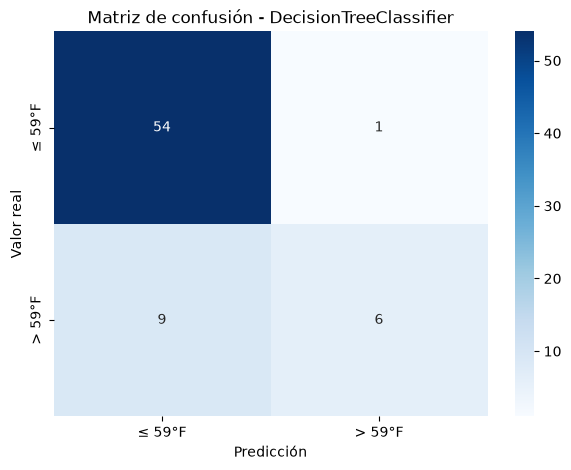

In [502]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['≤ 59°F', '> 59°F'],
    yticklabels=['≤ 59°F', '> 59°F']
)

plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.title('Matriz de confusión - DecisionTreeClassifier')
plt.show()

- Se ha entrenado un modelo DecisionTreeClassifier, optimizado mediante GridSearchCV y validación cruzada temporal, para predecir si la temperatura máxima diaria superará los 15 °C (59 °F).

- El modelo obtiene un Accuracy del 85,7 % y un F1 Macro del 73,0 % sobre el conjunto de Test.

- La matriz de confusión muestra que el clasificador identifica correctamente 54 de los 55 días fríos y 6 de los 15 días cálidos.

- Aunque el rendimiento global es elevado, el modelo presenta una diferencia importante entre ambas clases:

- Días fríos: Recall del 98,2 %.

- Días cálidos: Recall del 40 %.

- Esto indica que el modelo tiene una mayor capacidad para identificar días fríos, pero no consigue detectar el 60 % de los días que realmente superan los 59 °F.